# Truss Analyzer

*Note by Dr. Okte:*

Ash Levine took CEE244 in Fall 2024. Ash then became the student instructor of CEE244 in Fall 2025. She correctly identified that my Truss Analyzer could be and wrote the following code using classes instead of functions. I added an additional function to view the equation that the algorithm solves.

This code has the same functionality of the original one. However, it is easier to use!

Thanks Ash!

# Truss Analyzer - Ash Levine Version

I would recommend reading over the docstrings for the different functions if you want to use this. There are examples at the end as well as some general information. This should follow the same basic steps as the provided solver but using classes.

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import RegularPolygon, FancyArrowPatch, Circle

class TrussPoint:
    def __init__(self, coords, constraints=[0,0], forces=[0,0]):
        """
        Point class to store all the different points in the truss.
        Format is TrussPoint(coords=[x,y], constraints=[x,y], forces=[x,y])
        :param coords: coordinates of the point: [x,y]
        :param constraints: constraints on the point as 1-0 or True-False: [x,y]
        :param forces: forces at the point: [x,y]
        """
        self.coords = np.array(coords)
        self.constraints = np.array(constraints)
        self.forces = np.array(forces)

        # Class variable to store the resultant force if needed.
        self.resultants = np.array([None, None])

        # Class variable that keeps track of which rows in the solving matrix belong to it.
        self.row_index = None

    def __sub__ (self, other):
        """
        This is entirely abusive notation, but it will definitely save time.
        To clarify what this does, you can define functions like add, subtract, multiply, etc. for classes.
        So doing A - B will give a truss member from A to B.
        This is not how it this is supposed to work, as normally you would
        return another point or something with coordinates of A - B.
        :param self: first point
        :param other: second point
        :return: TrussMember from self to other
        """
        return TrussMember(self, other)

    def plot_horizontal(self, ax, maxload, magnitude, color):
        """
        Internal horizontal arrow function.
        You should not need to mess with this.
        :param ax: ax from the plot().
        :param maxload: scaling value from the plot().
        :param magnitude: what variable should be used for plotting?
        :param color: color of the arrow.
        """
        offset_x = np.sign(magnitude[0]) * maxload
        ax.add_patch(FancyArrowPatch((self.coords[0] - offset_x, self.coords[1]), (self.coords[0], self.coords[1]),
                                     arrowstyle='->', mutation_scale=20, color=color, zorder=10))
        ax.text(self.coords[0] - offset_x, self.coords[1], str(round(abs(magnitude[0]), 2)), ha='center', va='center',
                zorder=10)

    def plot_vertical(self, ax, maxload, magnitude, color):
        """
        Internal vertical arrow function.
        You should not need to mess with this.
        :param ax: ax from the plot().
        :param maxload: scaling value from the plot().
        :param magnitude: what variable should be used for plotting?
        :param color: color of the arrow.
        """
        offset_y = np.sign(magnitude[1]) * maxload
        ax.add_patch(FancyArrowPatch((self.coords[0], self.coords[1] - offset_y), (self.coords[0], self.coords[1]),
                                     arrowstyle='->', mutation_scale=20, color=color, zorder=10))
        ax.text(self.coords[0], self.coords[1] - offset_y, str(round(abs(magnitude[1]), 2)), ha='center', va='center',
                zorder=10)

    def plot(self, ax, aspect, is_solved):
        """
        Plots the forces on a point
        :param ax: ax from the plot().
        :param aspect: scaling value from the plot().
        :param is_solved: boolean of whether to do the solved or unsolved version.
        """
        # Calculate maxload based on aspect
        maxload = aspect / 10

        # Fixed support
        if self.constraints[0] == 1 and self.constraints[1] == 1:
            if is_solved:
                self.plot_horizontal(ax, maxload, self.resultants, 'blue')
                self.plot_vertical(ax, maxload, self.resultants, 'blue')
            else:
                side_length = aspect / 20
                h = side_length * np.sqrt(3) / 2
                x_center = self.coords[0]
                y_center = self.coords[1] - 2 * h / 3
                ax.add_patch(
                    RegularPolygon((x_center, y_center), numVertices=3, radius=side_length / np.sqrt(3), orientation=0,
                                   color='b'))

        # Horizontal roller
        elif self.constraints[0] == 1 and self.constraints[1] == 0:
            if is_solved:
                self.plot_horizontal(ax, maxload, self.resultants, 'blue')
            else:
                radius = aspect / 40
                ax.add_patch(Circle((self.coords[0] + radius, self.coords[1]), radius=radius, color='b'))

        # Vertical roller
        elif self.constraints[0] == 0 and self.constraints[1] == 1:
            if is_solved:
                self.plot_vertical(ax, maxload, self.resultants, 'blue')
            else:
                radius = aspect / 40
                ax.add_patch(Circle((self.coords[0], self.coords[1] - radius), radius=radius, color='b'))

        # Horizontal force load
        if abs(self.forces[0]) > 0:
            self.plot_horizontal(ax, maxload, self.forces, 'red')

        # Vertical force load
        if abs(self.forces[1]) > 0:
            self.plot_vertical(ax, maxload, self.forces, 'red')


class TrussMember:
    def __init__(self, from_point, to_point):
        """
        Member class to store relationships between points.
        If your labels are coming out upside down, try flipping the order you input a and b.
        :param from_point: point a.
        :param to_point: point b.
        """
        self.from_point = from_point
        self.to_point = to_point
        self.length = np.linalg.norm(self.to_point.coords - self.from_point.coords)
        self.components = (self.to_point.coords - self.from_point.coords) / self.length

        # Class variable to store the tension in the member once calculated.
        self.tension = None

    def plot(self, ax, colors, is_solved):
        """
        Plots the truss member and internal forces if applicable.
        :param ax: ax from the plot().
        :param colors: color of the truss member.
        :param is_solved: boolean of whether to do the solved or unsolved version.
        """
        # Makes the x and y lists
        x_values = [self.from_point.coords[0], self.to_point.coords[0]]
        y_values = [self.from_point.coords[1], self.to_point.coords[1]]

        # Plots the line
        ax.plot(x_values, y_values, color=colors, linewidth=2)

        if is_solved:
            # Computes the midpoint and rotation angle.
            midpoint = (self.from_point.coords + self.to_point.coords) / 2
            deltas = self.to_point.coords - self.from_point.coords
            angle = np.rad2deg(np.arctan2(deltas[1], deltas[0]))

            # Plots text if needed
            ax.text(midpoint[0], midpoint[1], str(round(self.tension, 2)), rotation=angle, ha='center', va='center')


def extract_points(points):
    """
    Internal function to get the coordinates of the points out of the point class.
    You should not need to mess with this.
    :param points: list of point classes.
    :return: list of coordinates of the points.
    """
    return np.array([[point.coords[0], point.coords[1]] for point in points])


class Truss:
    def __init__(self, members):
        """
        Class containing all the truss members and is where the magic happens.
        Format is Truss([AB, BC, AC, ...]).
        There is currently not duplication checking.
        You do not need to pass in the points as those are contained inside the member classes.
        :param members: members of the truss as a list.
        """
        # Adds members as a self variable
        self.members = members

        # Creates an empty list of points
        self.points = []

        # Creates empty variables A and b
        self.A = None
        self.b = None

        # Going through the list of members, add one copy of the point to the list, and update the point class to have an index pointing to the x and y respective indexes.
        # This is what enables the ability to pass in just the members and not the points.
        for mem in self.members:
            if not mem.from_point in self.points:
                self.points.append(mem.from_point)
                mem.from_point.row_index = 2 * self.points.index(mem.from_point)
            if not mem.to_point in self.points:
                self.points.append(mem.to_point)
                mem.to_point.row_index = 2 * self.points.index(mem.to_point)

    def check_det(self):
        """
        Checks for deterministic truss.
        :return: True if truss is deterministic
        """
        num_points = len(self.points)
        num_members = len(self.members)
        num_reactions = np.count_nonzero([point.constraints for point in self.points])
        if num_members + num_reactions < 2 * num_points:
            raise Exception('System is unstable!')
        if num_members + num_reactions > 2 * num_points:
            raise Exception('System is indeterminate!')
        return True

    def solve(self):
        """
        Function to solve the truss.
        I may add options to display intermediate results at a later date.
        There is no output by default as each member and point has it's values updated instead.
        """
        # Check for determinacy.
        self.check_det()

        # This is entirely because I do not want to redo all the instances of points and members to have self in front of them.
        points = self.points
        members = self.members

        # Calculating the amount of points and members we are dealing with.
        num_points = len(points)
        num_members = len(members)

        # Creates an array A twice as big as the points.
        # Creates an array b to hold the equals forces.
        A = np.zeros((num_points * 2, num_points * 2))
        b = np.zeros((num_points * 2, 1))

        # Adds the components of the internal forces to the array A.
        # This only operates on the left half, with each column being a member and each row being an x and y force at a point.
        # The second entry is mirrored because the forces are opposite.
        for col_index, mem in enumerate(members):
            A[mem.from_point.row_index:mem.from_point.row_index + 2, col_index] = mem.components
            A[mem.to_point.row_index:mem.to_point.row_index + 2, col_index] = -mem.components

        # Starts the counter at the right half of A, after the members,
        counter = num_members
        for point in points:
            # If there is a constraint than add a 1 to A.
            if point.constraints[0] > 0:
                A[point.row_index, counter] = point.constraints[0]
                counter += 1
            if point.constraints[1] > 0:
                A[point.row_index + 1, counter] = point.constraints[1]
                counter += 1

            # Populates the b array with the forces stored in the point class.
            b[point.row_index] = -point.forces[0]
            b[point.row_index + 1] = -point.forces[1]

        # Stores A and b into class variables.
        # Again because I don't want to rename all to self.
        self.A = A
        self.b = b

        # Solves the equation
        try:
            solved = np.linalg.solve(A, b)
        # It is possible to have a system that passes the determinacy test but is not possible to solve.
        except np.linalg.LinAlgError:
            raise Exception('While the system passes the determinacy test, it can not be solved.')

        # Populates the members to have the tension
        for row_index, mem in enumerate(members):
            mem.tension = solved[row_index, 0]

        # Resets the counter from earlier.
        counter = num_members
        for point in points:
            # The same logic from before but now we are storing the value of said forced.
            if point.constraints[0] > 0:
                point.resultants[0] = solved[counter, 0]
                counter += 1
            if point.constraints[1] > 0:
                point.resultants[1] = solved[counter, 0]
                counter += 1
    def matrix(self): #Added by Dr. Okte, to be able to see the equation
        from sympy import Matrix, Symbol, Eq, MatMul
        from IPython.display import display

        names = [
            next(name for name, obj in globals().items() if obj is member)
            for member in self.members
        ]

        for i, point in enumerate(self.points):
            for j, axis in enumerate(['x', 'y']):
                if point.constraints[j]:
                    names.append(f'R{i+1}{axis}')

        x = Matrix([Symbol(name) for name in names])

        #display(Eq(Matrix(self.A.round(3)) * x, Matrix(self.b), evaluate=False))

        # Display A × x = b without expanding
        print('Equation')
        display(Eq(MatMul(Matrix(self.A.round(3)), x, evaluate=False),
                Matrix(self.b), evaluate=False))
        print('\nExpanded')
        display(Eq(Matrix(self.A.round(3)) * x, Matrix(self.b), evaluate=False))
        # Display x = results
        print('\nResults')
        results = Matrix(np.linalg.solve(self.A, self.b).round(3))
        display(Eq(x, results, evaluate=False))

    def plot(self, is_solved=False):
        """
        Plots the truss system.
        This function DOES NOT call self.solve().
        Make sure to call self.solve() if is_solved is True.
        :param is_solved: boolean of whether to do the solved or unsolved version, default is False.
        """
        # This is entirely because I do not want to redo all the instances of points and members to have self in front of them.
        points = self.points
        members = self.members

        # Sets colors for the members
        if is_solved:
            colors = [0.75, 0.75, 0.75]
        else:
            colors = [0.1, 0.1, 0.1]

        # Sets the aspect scaling.
        aspect = max(np.max(extract_points(points)[:, 0]) - np.min(extract_points(points)[:, 0]),
                     np.max(extract_points(points)[:, 1]) - np.min(extract_points(points)[:, 1]))

        # To be completely honest, I am not sure why we need to do plt.subplots(), but the patches won't work otherwise.
        fig, ax = plt.subplots()
        ax.set_aspect('equal')
        plt.grid()

        # Plots the truss members.
        for member in members:
            member.plot(ax, colors, is_solved)

        # Plots the forces at each point.
        for point in points:
            point.plot(ax, aspect, is_solved)

        # Does some final formatting and plots.
        plt.axis('equal')
        plt.show()

# Example 1

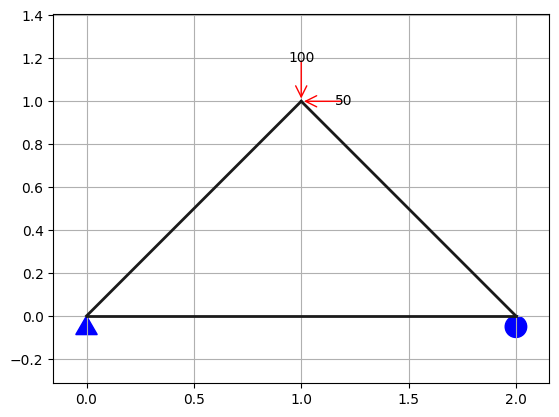

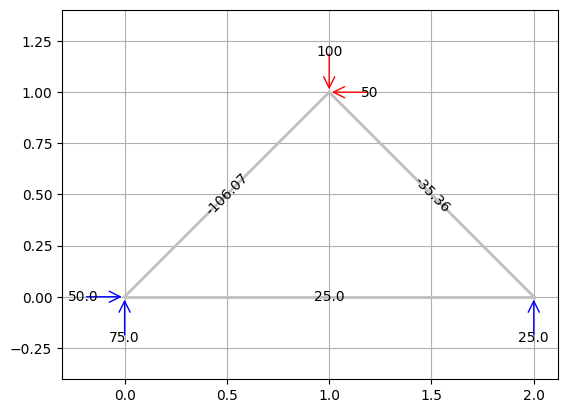

In [41]:
# Defining the points.
A = TrussPoint(coords=[0,0], constraints=[1,1], forces=[0,0])
B = TrussPoint([1,1], [0,0], [-50,-100])
C = TrussPoint([2,0], [0,1], [0,0])

# Defining the truss members.
AB = TrussMember(A, B)
BC = TrussMember(B, C)
AC = TrussMember(A, C)

# Initializing the truss.
T = Truss([AB, AC, BC])

# Plot the unsolved truss.
T.plot(False)

# Solve the truss and print coefficients.
# See the end code blocks for an explanation of the ordering.
T.solve()

# Plot the solved truss.
T.plot(True)

In [42]:
T.matrix()

Equation


Eq(Matrix([
[ 0.707,  1.0,    0.0, 1.0, 0.0, 0.0],
[ 0.707,  0.0,    0.0, 0.0, 1.0, 0.0],
[-0.707,  0.0,  0.707, 0.0, 0.0, 0.0],
[-0.707,  0.0, -0.707, 0.0, 0.0, 0.0],
[   0.0, -1.0, -0.707, 0.0, 0.0, 0.0],
[   0.0,  0.0,  0.707, 0.0, 0.0, 1.0]])*Matrix([
[ AB],
[ AC],
[ BC],
[R1x],
[R1y],
[R3y]]), Matrix([
[  0.0],
[  0.0],
[ 50.0],
[100.0],
[  0.0],
[  0.0]]))


Expanded


Eq(Matrix([
[0.707*AB + 1.0*AC + 1.0*R1x],
[         0.707*AB + 1.0*R1y],
[       -0.707*AB + 0.707*BC],
[       -0.707*AB - 0.707*BC],
[         -1.0*AC - 0.707*BC],
[         0.707*BC + 1.0*R3y]]), Matrix([
[  0.0],
[  0.0],
[ 50.0],
[100.0],
[  0.0],
[  0.0]]))


Results


Eq(Matrix([
[ AB],
[ AC],
[ BC],
[R1x],
[R1y],
[R3y]]), Matrix([
[-106.066],
[    25.0],
[ -35.355],
[    50.0],
[    75.0],
[    25.0]]))

# Example 2

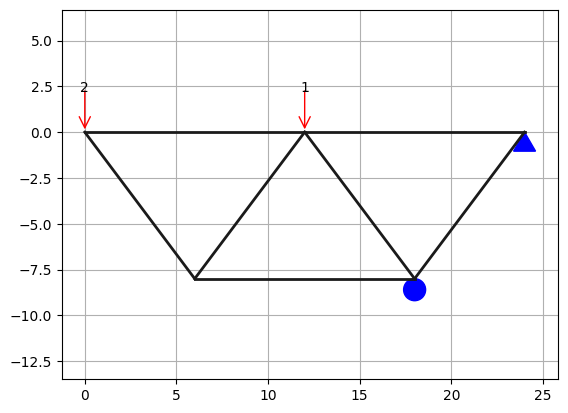

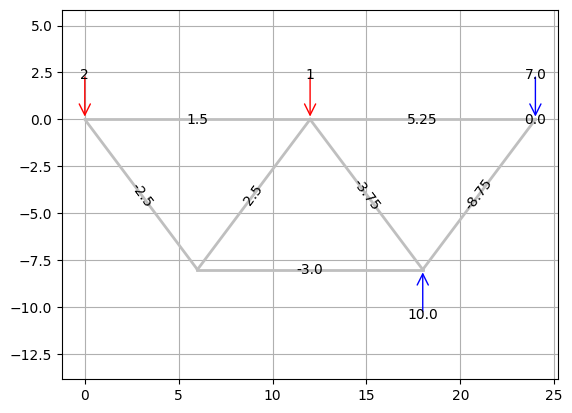

In [43]:
# Default values eliminate a lot of typing
A = TrussPoint([0,0], forces=[0,-2])
B = TrussPoint([6,-8])
C = TrussPoint([12,0], forces=[0,-1])
D = TrussPoint([18,-8], constraints=[0,1])
E = TrussPoint([24,0], constraints=[1,1])

# Also, you can use subtraction notation to easily denote truss members for large trusses
AB = A-B
AC = A-C
BC = B-C
BD = B-D
CD = C-D
CE = C-E
DE = D-E

T2 = Truss([AB, AC, BC, BD, CD, CE, DE])
T2.plot(False)
T2.solve()
T2.plot(True)

In [44]:
T2.matrix()

Equation


Eq(Matrix([
[ 0.6,  1.0,  0.0,  0.0,  0.0,  0.0,  0.0, 0.0, 0.0, 0.0],
[-0.8,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0, 0.0, 0.0, 0.0],
[-0.6,  0.0,  0.6,  1.0,  0.0,  0.0,  0.0, 0.0, 0.0, 0.0],
[ 0.8,  0.0,  0.8,  0.0,  0.0,  0.0,  0.0, 0.0, 0.0, 0.0],
[ 0.0, -1.0, -0.6,  0.0,  0.6,  1.0,  0.0, 0.0, 0.0, 0.0],
[ 0.0,  0.0, -0.8,  0.0, -0.8,  0.0,  0.0, 0.0, 0.0, 0.0],
[ 0.0,  0.0,  0.0, -1.0, -0.6,  0.0,  0.6, 0.0, 0.0, 0.0],
[ 0.0,  0.0,  0.0,  0.0,  0.8,  0.0,  0.8, 1.0, 0.0, 0.0],
[ 0.0,  0.0,  0.0,  0.0,  0.0, -1.0, -0.6, 0.0, 1.0, 0.0],
[ 0.0,  0.0,  0.0,  0.0,  0.0,  0.0, -0.8, 0.0, 0.0, 1.0]])*Matrix([
[ AB],
[ AC],
[ BC],
[ BD],
[ CD],
[ CE],
[ DE],
[R4y],
[R5x],
[R5y]]), Matrix([
[0.0],
[2.0],
[0.0],
[0.0],
[0.0],
[1.0],
[0.0],
[0.0],
[0.0],
[0.0]]))


Expanded


Eq(Matrix([
[                   0.6*AB + 1.0*AC],
[                           -0.8*AB],
[         -0.6*AB + 0.6*BC + 1.0*BD],
[                   0.8*AB + 0.8*BC],
[-1.0*AC - 0.6*BC + 0.6*CD + 1.0*CE],
[                  -0.8*BC - 0.8*CD],
[         -1.0*BD - 0.6*CD + 0.6*DE],
[         0.8*CD + 0.8*DE + 1.0*R4y],
[        -1.0*CE - 0.6*DE + 1.0*R5x],
[                 -0.8*DE + 1.0*R5y]]), Matrix([
[0.0],
[2.0],
[0.0],
[0.0],
[0.0],
[1.0],
[0.0],
[0.0],
[0.0],
[0.0]]))


Results


Eq(Matrix([
[ AB],
[ AC],
[ BC],
[ BD],
[ CD],
[ CE],
[ DE],
[R4y],
[R5x],
[R5y]]), Matrix([
[ -2.5],
[  1.5],
[  2.5],
[ -3.0],
[-3.75],
[ 5.25],
[-8.75],
[ 10.0],
[  0.0],
[ -7.0]]))

# Example 3

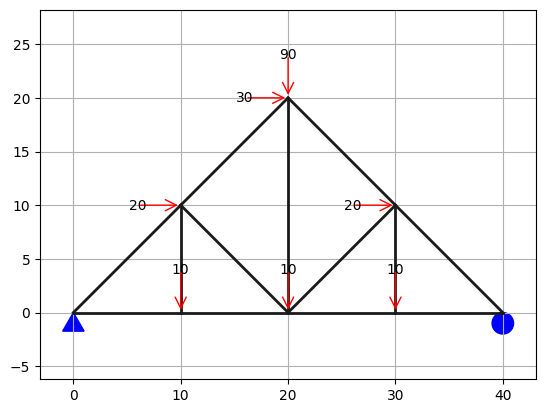

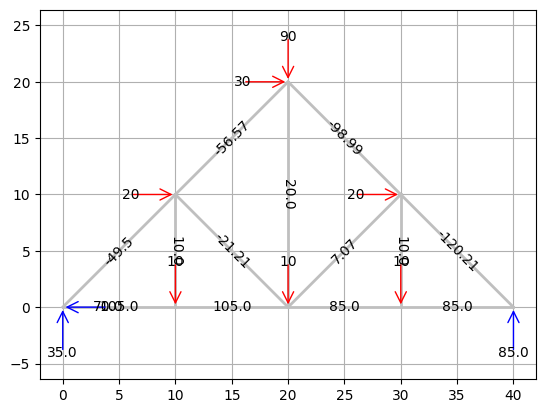

In [45]:
A = TrussPoint([0,0], constraints=[1,1])
B = TrussPoint([10,0], forces=[0,-10])
C = TrussPoint([20,0], forces=[0,-10])
D = TrussPoint([30,0], forces=[0,-10])
E = TrussPoint([40,0], constraints=[0,1])
F = TrussPoint([10,10], forces=[20,0])
G = TrussPoint([20,20], forces=[30,-90])
H = TrussPoint([30,10], forces=[20,0])

# I made this example before adding the subtraction notation but see example 2
# for a quicker way of doing this.
AB = TrussMember(A, B)
BC = TrussMember(B, C)
CD = TrussMember(C, D)
DE = TrussMember(D, E)
AF = TrussMember(A, F)
FB = TrussMember(F, B)
FC = TrussMember(F, C)
FG = TrussMember(F, G)
GC = TrussMember(G, C)
GH = TrussMember(G, H)
CH = TrussMember(C, H)
HD = TrussMember(H, D)
HE = TrussMember(H, E)

T3 = Truss([AB,BC,CD,DE,AF,FB,FC,FG,GC,GH,CH,HD,HE])
T3.plot(False)
T3.solve()
T3.plot(True)

In [46]:
T3.matrix()

Equation


Eq(Matrix([
[ 1.0,  0.0,  0.0,  0.0,  0.707,  0.0,    0.0,    0.0,  0.0,    0.0,    0.0,  0.0,    0.0, 1.0, 0.0, 0.0],
[ 0.0,  0.0,  0.0,  0.0,  0.707,  0.0,    0.0,    0.0,  0.0,    0.0,    0.0,  0.0,    0.0, 0.0, 1.0, 0.0],
[-1.0,  1.0,  0.0,  0.0,    0.0,  0.0,    0.0,    0.0,  0.0,    0.0,    0.0,  0.0,    0.0, 0.0, 0.0, 0.0],
[ 0.0,  0.0,  0.0,  0.0,    0.0,  1.0,    0.0,    0.0,  0.0,    0.0,    0.0,  0.0,    0.0, 0.0, 0.0, 0.0],
[ 0.0, -1.0,  1.0,  0.0,    0.0,  0.0, -0.707,    0.0,  0.0,    0.0,  0.707,  0.0,    0.0, 0.0, 0.0, 0.0],
[ 0.0,  0.0,  0.0,  0.0,    0.0,  0.0,  0.707,    0.0,  1.0,    0.0,  0.707,  0.0,    0.0, 0.0, 0.0, 0.0],
[ 0.0,  0.0, -1.0,  1.0,    0.0,  0.0,    0.0,    0.0,  0.0,    0.0,    0.0,  0.0,    0.0, 0.0, 0.0, 0.0],
[ 0.0,  0.0,  0.0,  0.0,    0.0,  0.0,    0.0,    0.0,  0.0,    0.0,    0.0,  1.0,    0.0, 0.0, 0.0, 0.0],
[ 0.0,  0.0,  0.0, -1.0,    0.0,  0.0,    0.0,    0.0,  0.0,    0.0,    0.0,  0.0, -0.707, 0.0, 0.0, 0.0],
[ 0.0,  0.0,  0.0,  0.0, 


Expanded


Eq(Matrix([
[             1.0*AB + 0.707*AF + 1.0*R1x],
[                      0.707*AF + 1.0*R1y],
[                        -1.0*AB + 1.0*BC],
[                                  1.0*FB],
[  -1.0*BC + 1.0*CD + 0.707*CH - 0.707*FC],
[            0.707*CH + 0.707*FC + 1.0*GC],
[                        -1.0*CD + 1.0*DE],
[                                  1.0*HD],
[                      -1.0*DE - 0.707*HE],
[                      0.707*HE + 1.0*R5y],
[         -0.707*AF + 0.707*FC + 0.707*FG],
[-0.707*AF - 1.0*FB - 0.707*FC + 0.707*FG],
[                    -0.707*FG + 0.707*GH],
[           -0.707*FG - 1.0*GC - 0.707*GH],
[         -0.707*CH - 0.707*GH + 0.707*HE],
[-0.707*CH + 0.707*GH - 1.0*HD - 0.707*HE]]), Matrix([
[  0.0],
[  0.0],
[  0.0],
[ 10.0],
[  0.0],
[ 10.0],
[  0.0],
[ 10.0],
[  0.0],
[  0.0],
[-20.0],
[  0.0],
[-30.0],
[ 90.0],
[-20.0],
[  0.0]]))


Results


Eq(Matrix([
[ AB],
[ BC],
[ CD],
[ DE],
[ AF],
[ FB],
[ FC],
[ FG],
[ GC],
[ GH],
[ CH],
[ HD],
[ HE],
[R1x],
[R1y],
[R5y]]), Matrix([
[   105.0],
[   105.0],
[    85.0],
[    85.0],
[ -49.497],
[    10.0],
[ -21.213],
[ -56.569],
[    20.0],
[ -98.995],
[   7.071],
[    10.0],
[-120.208],
[   -70.0],
[    35.0],
[    85.0]]))

# Extra Information

In [ ]:
"""
Just to demonstrate, if you say, only need the tension in member FB, which is currently blocked,
you can just do the following:
"""
FB.tension

10.0

In [ ]:
"""
In addition, the output order of the array will always be the tensions in the members in the order you put them in,
followed by the resultant forces.
Each force will if applicable, appear in the order in which that point first appeared to the truss solver,
and then the x and y forces.
This means that the order of points in the example above is:
A, B, C, D, E, F, G, H.

Now that is because of the order they were inputted. If we put member DE before BC, then the order becomes:
A, B, D, E, C, F, G, H.

And if member DE was actually ED = TrussMember(E,D), then the order becomes:
A, B, E, D, C, F, G, H.

This only really matters if you are trying to get information from the matrix itself.
In reality, the resultant forces get added to the point all the same, and can be retrieved in the following way:
"""
A.resultants

array([-70.0, 35.0], dtype=object)

In [ ]:
"""
Lastly, if for whatever reson you need either the A or b arrays from the truss,
they are attributes of the truss and can be called like any other class variable.
"""
T2.A

array([[ 0.6,  1. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ],
       [-0.8,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ],
       [-0.6,  0. ,  0.6,  1. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ],
       [ 0.8,  0. ,  0.8,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ,  0. ],
       [ 0. , -1. , -0.6,  0. ,  0.6,  1. ,  0. ,  0. ,  0. ,  0. ],
       [ 0. , -0. , -0.8,  0. , -0.8,  0. ,  0. ,  0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. , -1. , -0.6,  0. ,  0.6,  0. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. , -0. ,  0.8,  0. ,  0.8,  1. ,  0. ,  0. ],
       [ 0. ,  0. ,  0. ,  0. ,  0. , -1. , -0.6,  0. ,  1. ,  0. ],
       [ 0. ,  0. ,  0. ,  0. ,  0. , -0. , -0.8,  0. ,  0. ,  1. ]])